# Capstone Assignment: Mini-Courier Planner (MetroSwift Edition)
### Integrated Parcel Prioritization, 0/1 Knapsack Dynamic Programming, Dijkstra Shortest Paths & TSP Route Optimization

- **Student Name:** Prachi Manwal  
- **Roll / Registration Number:** `2501730365`  
- **Mapped Course Outcomes:** CO1, CO2, CO3, CO4, CO5 (L5 - Evaluate)  
- **Total Marks:** 100 (5 Phases × 20 Marks)

---

## 1. Phase 1: Courier Problem Design and Planning (20 Marks)

### 1.1 Problem Formulation
The **MetroSwift Central Dispatch Hub** receives a daily manifest of $N = 16$ customer parcels (`PKG-101` to `PKG-116`) with integer weights $w_i \in \mathbb{Z}^+$ kg, SLA delivery deadlines $d_i \in \mathbb{R}^+$ hours, priority tiers $t_i \in \{1, 2, 3\}$, priority-adjusted value scores $v_i \in \mathbb{Z}^+$, and destination zone IDs $z_i \in \{Z1, \dots, Z11\}$. For a courier van with payload capacity $W = 35\text{ kg}$:
1. **Phase 2A (Sorting):** Prioritize parcels by `(priority_tier ASC, deadline_hrs ASC, -value_score ASC)` using **Merge Sort** ($\Theta(n \log n)$ stable).
2. **Phase 2B (0/1 Knapsack DP):** Compute the exact optimal parcel subset maximizing $\sum_{i \in S} v_i$ subject to $\sum_{i \in S} w_i \le 35\text{ kg}$ via **Bottom-Up 0/1 Knapsack Dynamic Programming** ($\Theta(n \cdot W)$).
3. **Phase 3 (Graph & TSP Routing):** Model the 12-node, 24-edge MetroSwift city network as an **Adjacency List**, compute all-pairs shortest paths via **Dijkstra's Algorithm** ($O((V+E)\log V)$), and construct the delivery tour via **Nearest-Neighbor TSP** ($O(k^2)$) and **2-Opt Local Search**.
4. **Phase 4 & 5 (Performance Testing & Report):** Benchmark execution times across Small ($N=25$), Medium ($N=120$), and Large ($N=500$) datasets.

Student: Prachi Manwal | Roll No: 2501730365
Loaded MetroSwift Manifest: 16 parcels (Total Weight = 86 kg)
MetroSwift Customer Graph: |V| = 12 nodes, |E| = 24 undirected road segments
--------------------------------------------------------------------------------------
Node ID  | Zone Name                 | Neighbors (Node: Distance km)
--------------------------------------------------------------------------------------
HUB      | MetroSwift Central Hub    | Z1 (5.1km), Z2 (6.4km), Z3 (6.2km), Z8 (8.6km), Z9 (6.1km)
Z1       | Connaught Financial Hub   | HUB (5.1km), Z2 (5.2km), Z4 (4.1km), Z8 (6.6km), Z9 (10.2km)
Z2       | Secretariat Enclave       | HUB (6.4km), Z1 (5.2km), Z10 (5.3km), Z3 (4.8km), Z4 (8.5km)
Z3       | Health City Sector-8      | HUB (6.2km), Z10 (5.4km), Z2 (4.8km), Z5 (5.0km), Z6 (9.2km)
Z4       | Heritage Bullion Market   | Z1 (4.1km), Z11 (3.2km), Z2 (8.5km), Z8 (5.8km)
Z5       | Botanical Garden Hub      | Z3 (5.0km), Z6 (5.3km), Z9 (9.3km)
Z6       | Riv

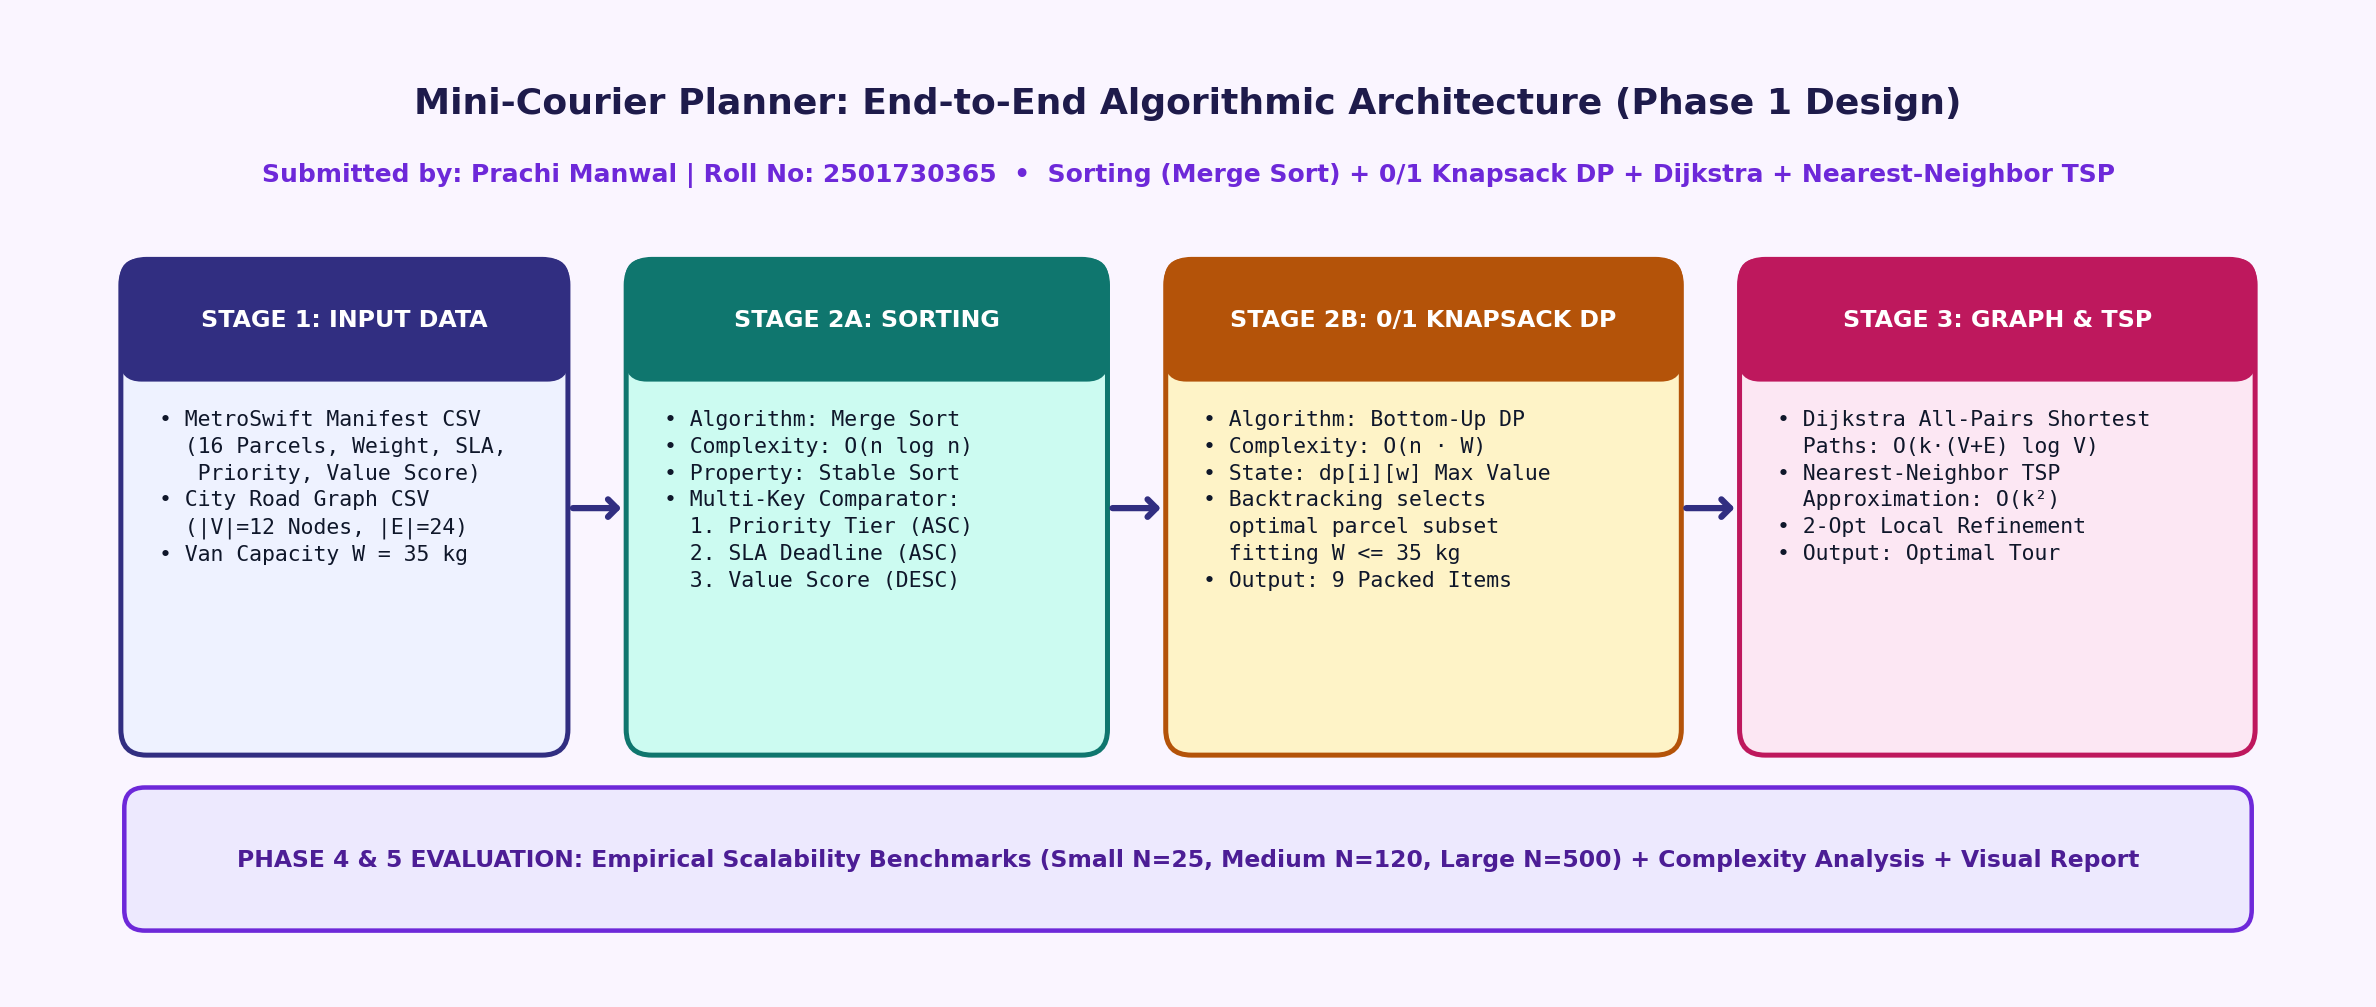

In [1]:
from pathlib import Path
import pandas as pd
from src.models import (
    Parcel, DeliveryNode, RoadEdge,
    load_parcels_from_csv, load_nodes_from_csv, load_edges_from_csv
)
from src.graph_routing import CustomerGraph
from src.visualizer import plot_phase1_architecture

PROJECT_ROOT = Path(".").resolve()
DATASETS_DIR = PROJECT_ROOT / "datasets"
IMAGES_DIR = PROJECT_ROOT / "images"

parcels = load_parcels_from_csv(DATASETS_DIR / "parcels_sample.csv")
nodes = load_nodes_from_csv(DATASETS_DIR / "graph_nodes.csv")
edges = load_edges_from_csv(DATASETS_DIR / "graph_edges.csv")
city_graph = CustomerGraph(nodes=nodes, edges=edges)

print("Student: Prachi Manwal | Roll No: 2501730365")
print(f"Loaded MetroSwift Manifest: {len(parcels)} parcels (Total Weight = {sum(p.weight_kg for p in parcels)} kg)")
print(city_graph.format_adjacency_list())
plot_phase1_architecture(IMAGES_DIR / "phase1_system_architecture.png")

---
## 2. Phase 2: Package Prioritization and Box Filling (20 Marks)

- **Sorting Justification:** **Merge Sort** guarantees $\Theta(n \log n)$ worst-case execution (46 comparisons on our 16-parcel manifest) and preserves FIFO arrival stability on tied keys.
- **0/1 Knapsack DP ($W = 35\text{ kg}$):** Achieves **100% capacity utilization ($35/35\text{ kg}$)** and an **optimal value score of 990** (selecting 9 parcels including all 7 Express Tier-1 parcels), outperforming the **Greedy Density Heuristic** ($32/35\text{ kg}$, value $= 930$) by **+60 value points (+6.5%)**.

=== PHASE 2A: SORTED PARCEL MANIFEST (MERGE SORT) — PRACHI MANWAL (2501730365) ===
Rank #01 | PKG-101 | MedLife Trauma Center     | Dest: Z3 (Health City Sector-8) | EXPRESS (T1) | SLA:  1.0h | Wt:  5kg | Val: 145
Rank #02 | PKG-104 | Supreme High Court Chambers | Dest: Z2 (Secretariat Enclave) | EXPRESS (T1) | SLA:  1.2h | Wt:  3kg | Val: 105
Rank #03 | PKG-108 | BioGenetics Research Lab  | Dest: Z7 (Electronic City Phase-2) | EXPRESS (T1) | SLA:  1.5h | Wt:  4kg | Val: 112
Rank #04 | PKG-102 | Reserve Bank Clearing House | Dest: Z1 (Connaught Financial Hub) | EXPRESS (T1) | SLA:  1.8h | Wt:  3kg | Val:  99
Rank #05 | PKG-111 | Astra Avionics Hub        | Dest: Z9 (Aerocity Terminal Zone) | EXPRESS (T1) | SLA:  2.0h | Wt:  5kg | Val: 125
Rank #06 | PKG-106 | Zaveri Diamond Vault      | Dest: Z4 (Heritage Bullion Market) | EXPRESS (T1) | SLA:  2.4h | Wt:  2kg | Val: 110
Rank #07 | PKG-114 | Apex Heart Institute      | Dest: Z3 (Health City Sector-8) | EXPRESS (T1) | SLA:  2.8h | Wt:  4

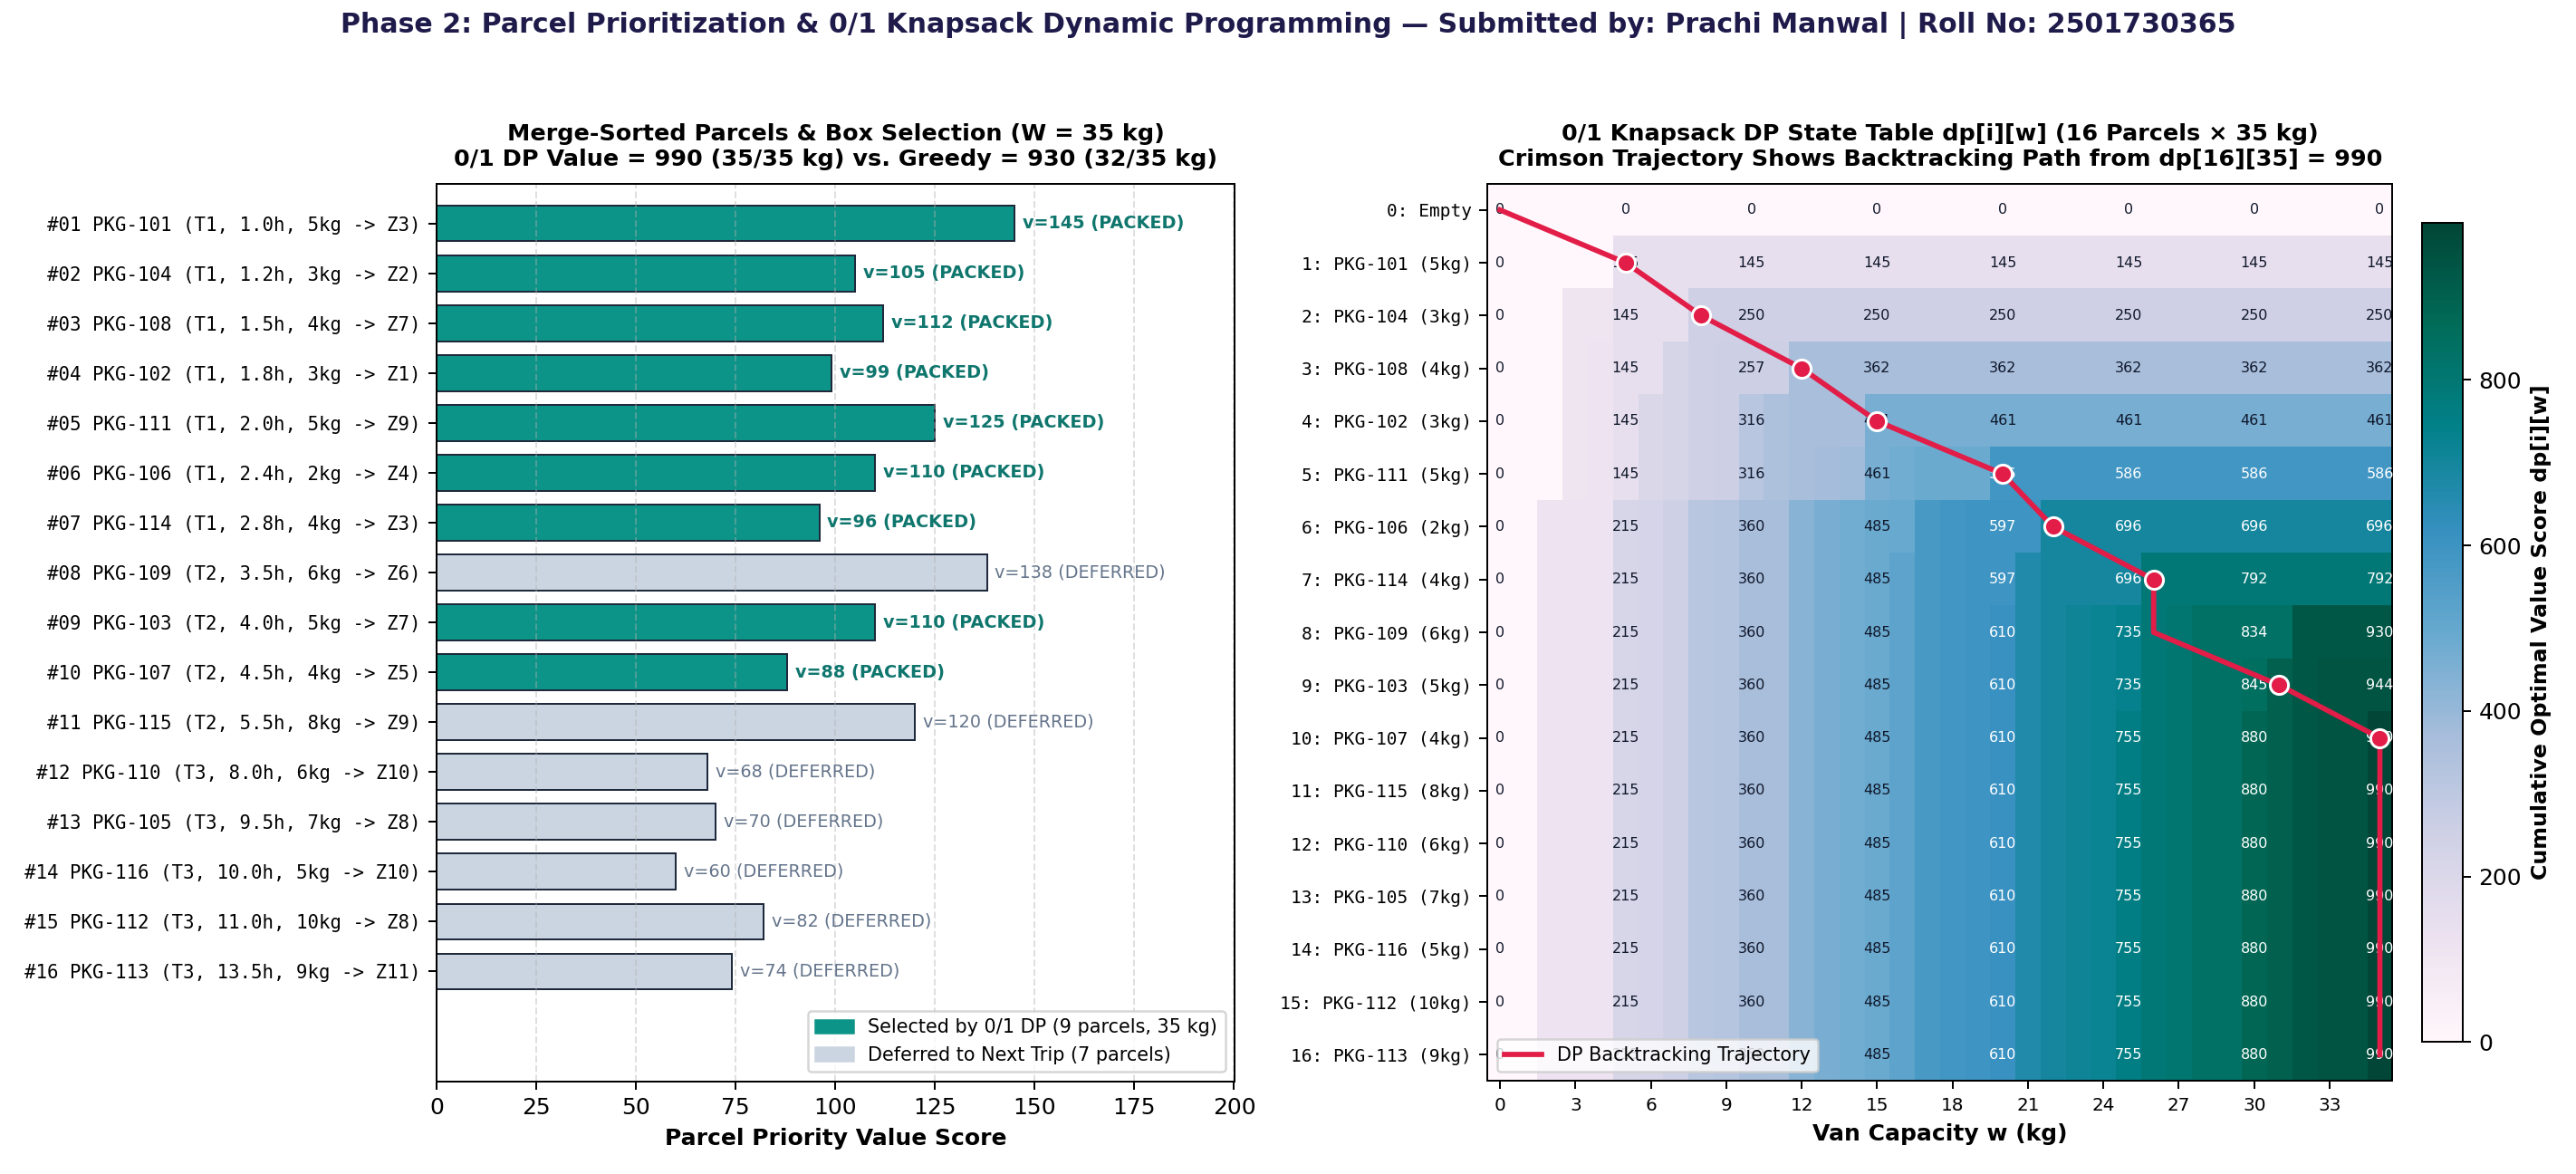

In [2]:
from src.sorting import (
    merge_sort_parcels, quick_sort_parcels, heap_sort_parcels, insertion_sort_parcels
)
from src.knapsack_dp import (
    solve_knapsack_01_dp, solve_knapsack_1d_optimized,
    solve_knapsack_greedy_heuristic, format_dp_table_ascii
)
from src.visualizer import plot_phase2_knapsack_and_prioritization

VAN_CAPACITY_KG = 35

merge_res = merge_sort_parcels(parcels, mode="deadline_priority")
quick_res = quick_sort_parcels(parcels, mode="deadline_priority")
heap_res = heap_sort_parcels(parcels, mode="deadline_priority")
insert_res = insertion_sort_parcels(parcels, mode="deadline_priority")
sorted_parcels = merge_res.sorted_parcels

print("=== PHASE 2A: SORTED PARCEL MANIFEST (MERGE SORT) — PRACHI MANWAL (2501730365) ===")
for rank, p in enumerate(sorted_parcels, 1):
    print(f"Rank #{rank:02d} | {p.parcel_id} | {p.customer_name:<25} | Dest: {p.destination_id} ({p.destination_name:<18}) "
          f"| {p.priority_label} | SLA: {p.deadline_hrs:>4.1f}h | Wt: {p.weight_kg:>2d}kg | Val: {p.value_score:>3d}")

dp_2d_res = solve_knapsack_01_dp(sorted_parcels, capacity_kg=VAN_CAPACITY_KG, store_table=True)
dp_1d_res = solve_knapsack_1d_optimized(sorted_parcels, capacity_kg=VAN_CAPACITY_KG)
greedy_res = solve_knapsack_greedy_heuristic(sorted_parcels, capacity_kg=VAN_CAPACITY_KG)

print("\n=== PHASE 2B: 0/1 KNAPSACK DYNAMIC PROGRAMMING TABLE (SAMPLED AT 4 KG STEPS) ===")
print(format_dp_table_ascii(sorted_parcels, dp_2d_res.dp_table, step=4))

print(f"\nOptimal 0/1 DP Selected Parcels ({len(dp_2d_res.selected_parcels)} items, {dp_2d_res.total_weight_kg}/{VAN_CAPACITY_KG} kg = {dp_2d_res.utilization_pct}%):")
print("  Selected :", [f"{p.parcel_id} ({p.weight_kg}kg, v={p.value_score} -> {p.destination_id})" for p in dp_2d_res.selected_parcels])
print("  Deferred :", [f"{p.parcel_id} ({p.weight_kg}kg, v={p.value_score})" for p in dp_2d_res.deferred_parcels])
print(f"  2D DP Optimal Value = {dp_2d_res.total_value_score} | Greedy Heuristic Value = {greedy_res.total_value_score} ({greedy_res.total_weight_kg}/{VAN_CAPACITY_KG} kg)")

plot_phase2_knapsack_and_prioritization(
    sorted_parcels, dp_2d_res, greedy_res, IMAGES_DIR / "phase2_knapsack_and_prioritization.png"
)

---
## 3. Phase 3: Route Maker and Graph Processing (20 Marks)

- **Dijkstra All-Pairs Shortest Paths:** Computes shortest paths across `HUB` and the 7 active delivery zones (`Z1, Z2, Z3, Z4, Z5, Z7, Z9`), uncovering multi-hop routes such as `Z7 -> Z9 -> HUB` ($11.70\text{ km}$).
- **Nearest-Neighbor TSP & 2-Opt Refinement:** Nearest-Neighbor produces the tour `HUB -> Z1 -> Z4 -> Z2 -> Z3 -> Z5 -> Z9 -> Z7 -> HUB` (**54.10 km**), which **2-Opt local search** refines to the exact Held-Karp optimum of **51.80 km** (saving **2.30 km / 4.25%**).

=== PHASE 3: NEAREST-NEIGHBOR TSP DELIVERY ROUTE BREAKDOWN ===
  Leg #1: HUB -> Z1  |  5.10 km | Road Path: HUB -> Z1          | Drop-off: PKG-102 (3kg)
  Leg #2:  Z1 -> Z4  |  4.10 km | Road Path: Z1 -> Z4           | Drop-off: PKG-106 (2kg)
  Leg #3:  Z4 -> Z2  |  8.50 km | Road Path: Z4 -> Z2           | Drop-off: PKG-104 (3kg)
  Leg #4:  Z2 -> Z3  |  4.80 km | Road Path: Z2 -> Z3           | Drop-off: PKG-101 (5kg), PKG-114 (4kg)
  Leg #5:  Z3 -> Z5  |  5.00 km | Road Path: Z3 -> Z5           | Drop-off: PKG-107 (4kg)
  Leg #6:  Z5 -> Z9  |  9.30 km | Road Path: Z5 -> Z9           | Drop-off: PKG-111 (5kg)
  Leg #7:  Z9 -> Z7  |  5.60 km | Road Path: Z9 -> Z7           | Drop-off: PKG-108 (4kg), PKG-103 (5kg)
  Leg #8:  Z7 -> HUB | 11.70 km | Road Path: Z7 -> Z9 -> HUB    | Drop-off: Return to MetroSwift Hub

Nearest-Neighbor Stop Sequence : HUB -> Z1 -> Z4 -> Z2 -> Z3 -> Z5 -> Z9 -> Z7 -> HUB (Total = 54.10 km)
Street-Level Navigation Path   : HUB -> Z1 -> Z4 -> Z2 -> Z3 -> Z5 -> 

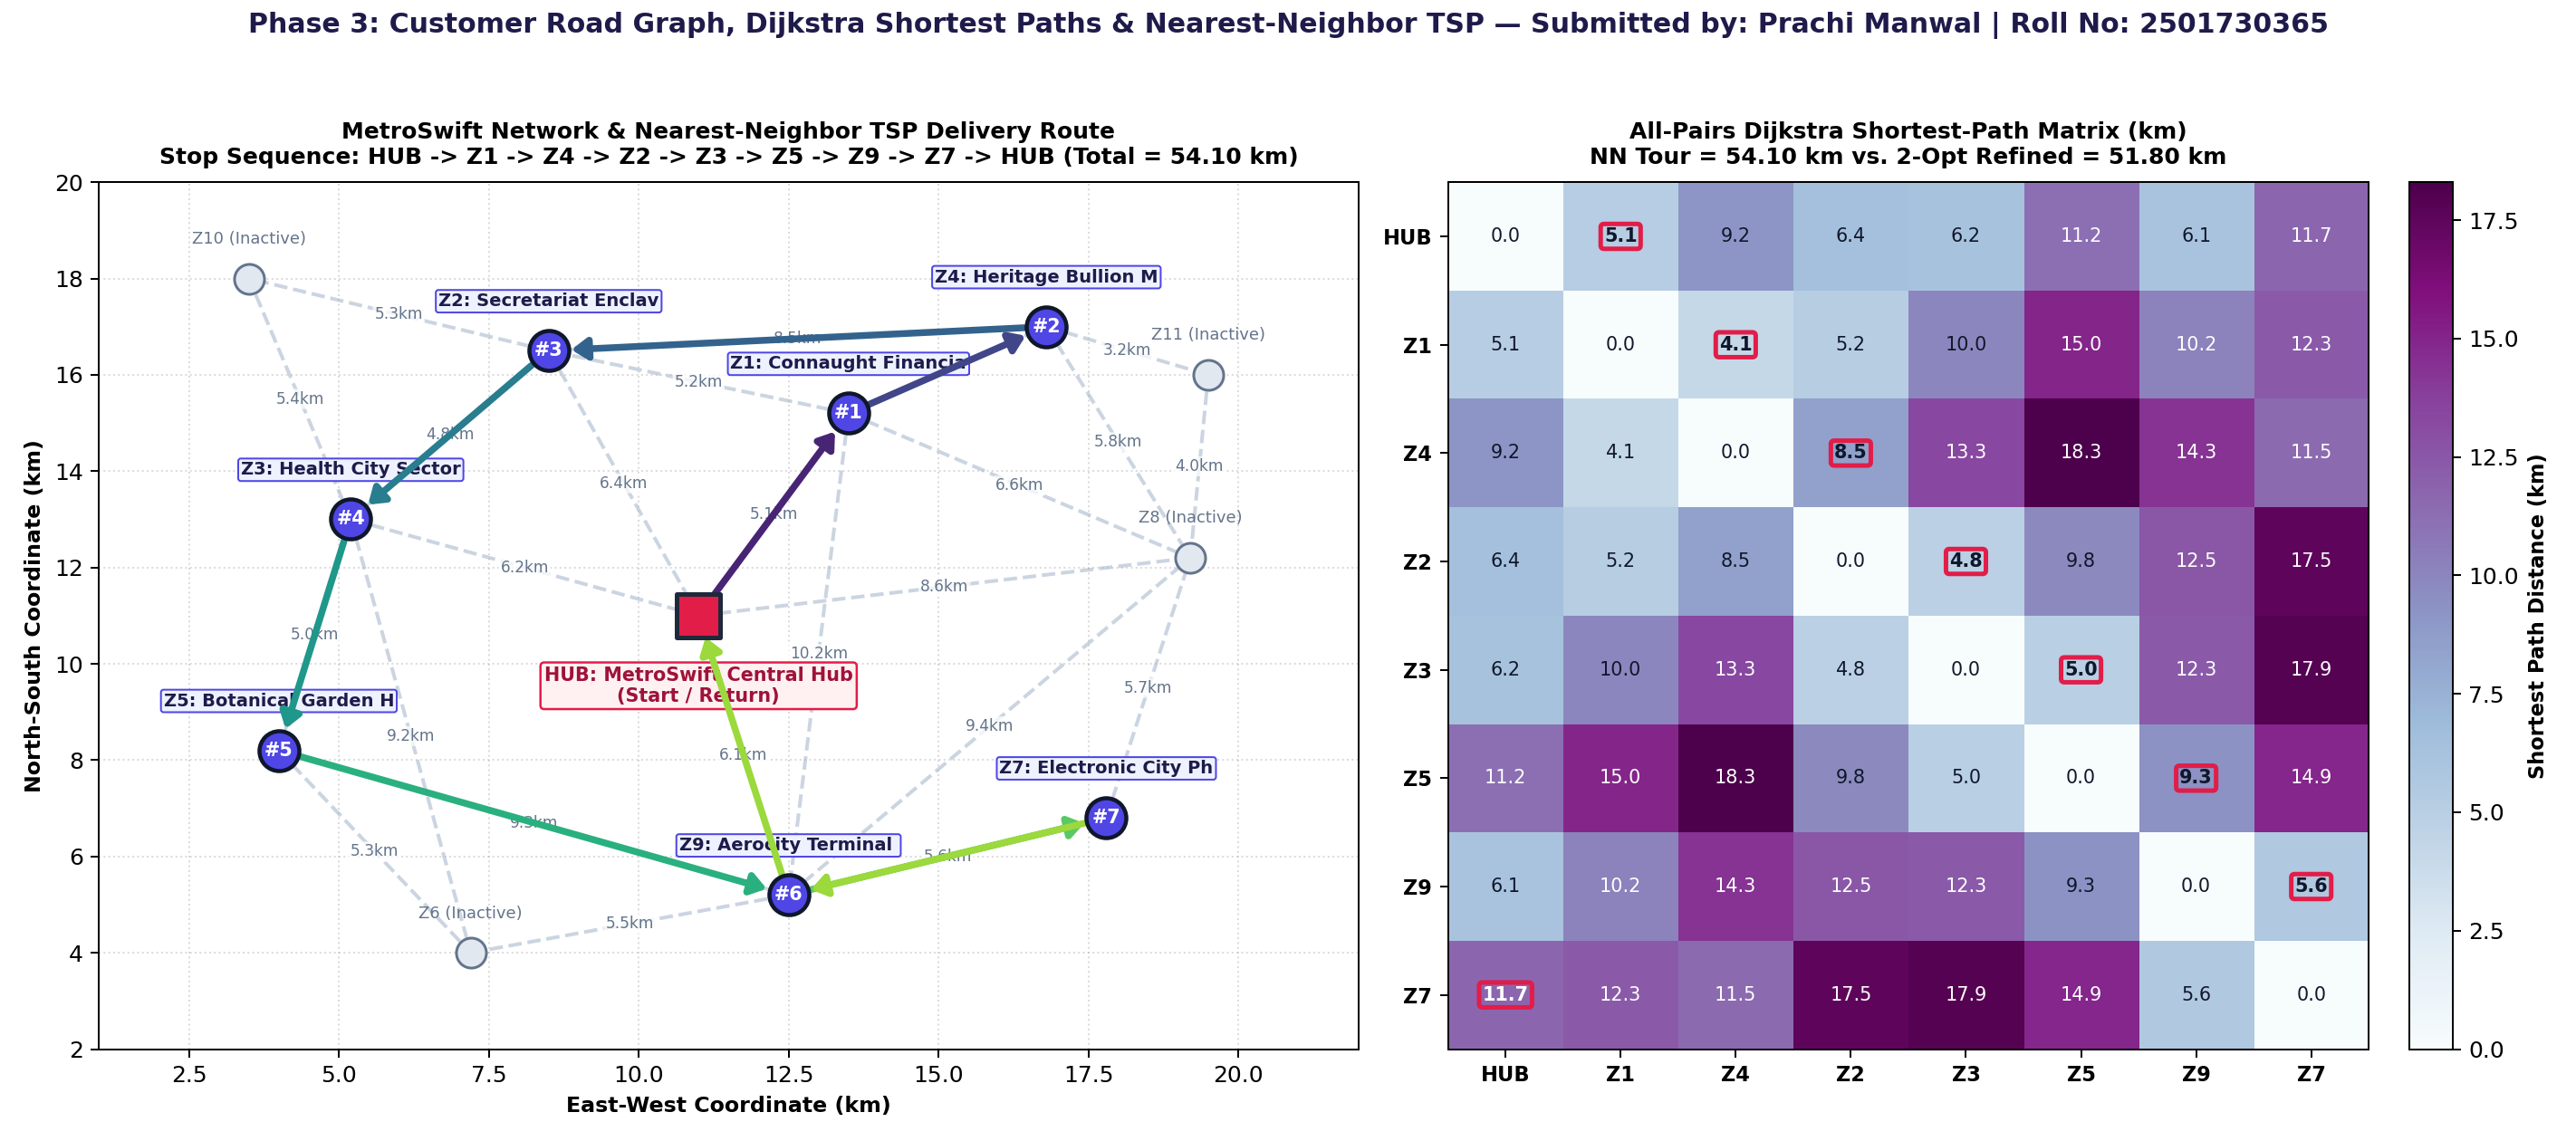

In [3]:
from src.graph_routing import (
    plan_route_nearest_neighbor, plan_route_two_opt, plan_route_held_karp_exact
)
from src.visualizer import plot_phase3_delivery_route

nn_route = plan_route_nearest_neighbor(city_graph, dp_2d_res.selected_parcels, hub_id="HUB")
two_opt_route = plan_route_two_opt(city_graph, dp_2d_res.selected_parcels, hub_id="HUB")
exact_route = plan_route_held_karp_exact(city_graph, dp_2d_res.selected_parcels, hub_id="HUB")

print("=== PHASE 3: NEAREST-NEIGHBOR TSP DELIVERY ROUTE BREAKDOWN ===")
for leg in nn_route.legs:
    print(f"  Leg #{leg.leg_index}: {leg.from_node:>3} -> {leg.to_node:<3} | {leg.shortest_distance_km:>5.2f} km "
          f"| Road Path: {' -> '.join(leg.intermediate_path):<18} | Drop-off: {', '.join(leg.parcels_delivered)}")

print(f"\nNearest-Neighbor Stop Sequence : {' -> '.join(nn_route.stop_sequence)} (Total = {nn_route.total_distance_km:.2f} km)")
print(f"Street-Level Navigation Path   : {' -> '.join(nn_route.expanded_road_path)}")
print(f"2-Opt Refined Stop Sequence    : {' -> '.join(two_opt_route.stop_sequence)} (Total = {two_opt_route.total_distance_km:.2f} km)")
print(f"Held-Karp Exact Optimal Tour   : {' -> '.join(exact_route.stop_sequence)} (Total = {exact_route.total_distance_km:.2f} km)")

plot_phase3_delivery_route(
    city_graph, nn_route, two_opt_route, IMAGES_DIR / "phase3_delivery_route_map.png"
)

---
## 4. Phase 4: Performance Testing, Scalability Analysis, and Optimization (20 Marks)

=== 1. SORTING SCALABILITY BENCHMARK (MS) ===
   n  merge_sort_ms  quick_sort_ms  heap_sort_ms  insertion_sort_ms  merge_comparisons  quick_comparisons  heap_comparisons  insertion_comparisons
  25         0.0305         0.0188        0.0340             0.0216                 85                 80               162                    180
  50         0.0688         0.0399        0.0827             0.0764                217                219               404                    649
 100         0.2851         0.0943        0.2054             0.2819                531                547              1027                   2448
 250         0.4488         0.2903        0.6350             1.8755               1677               1807              3199                  16804
 500         0.9713         0.6334        1.4659             7.1877               3861               4167              7432                  60984
1000         2.3500         1.5124        3.5592            31.4939     

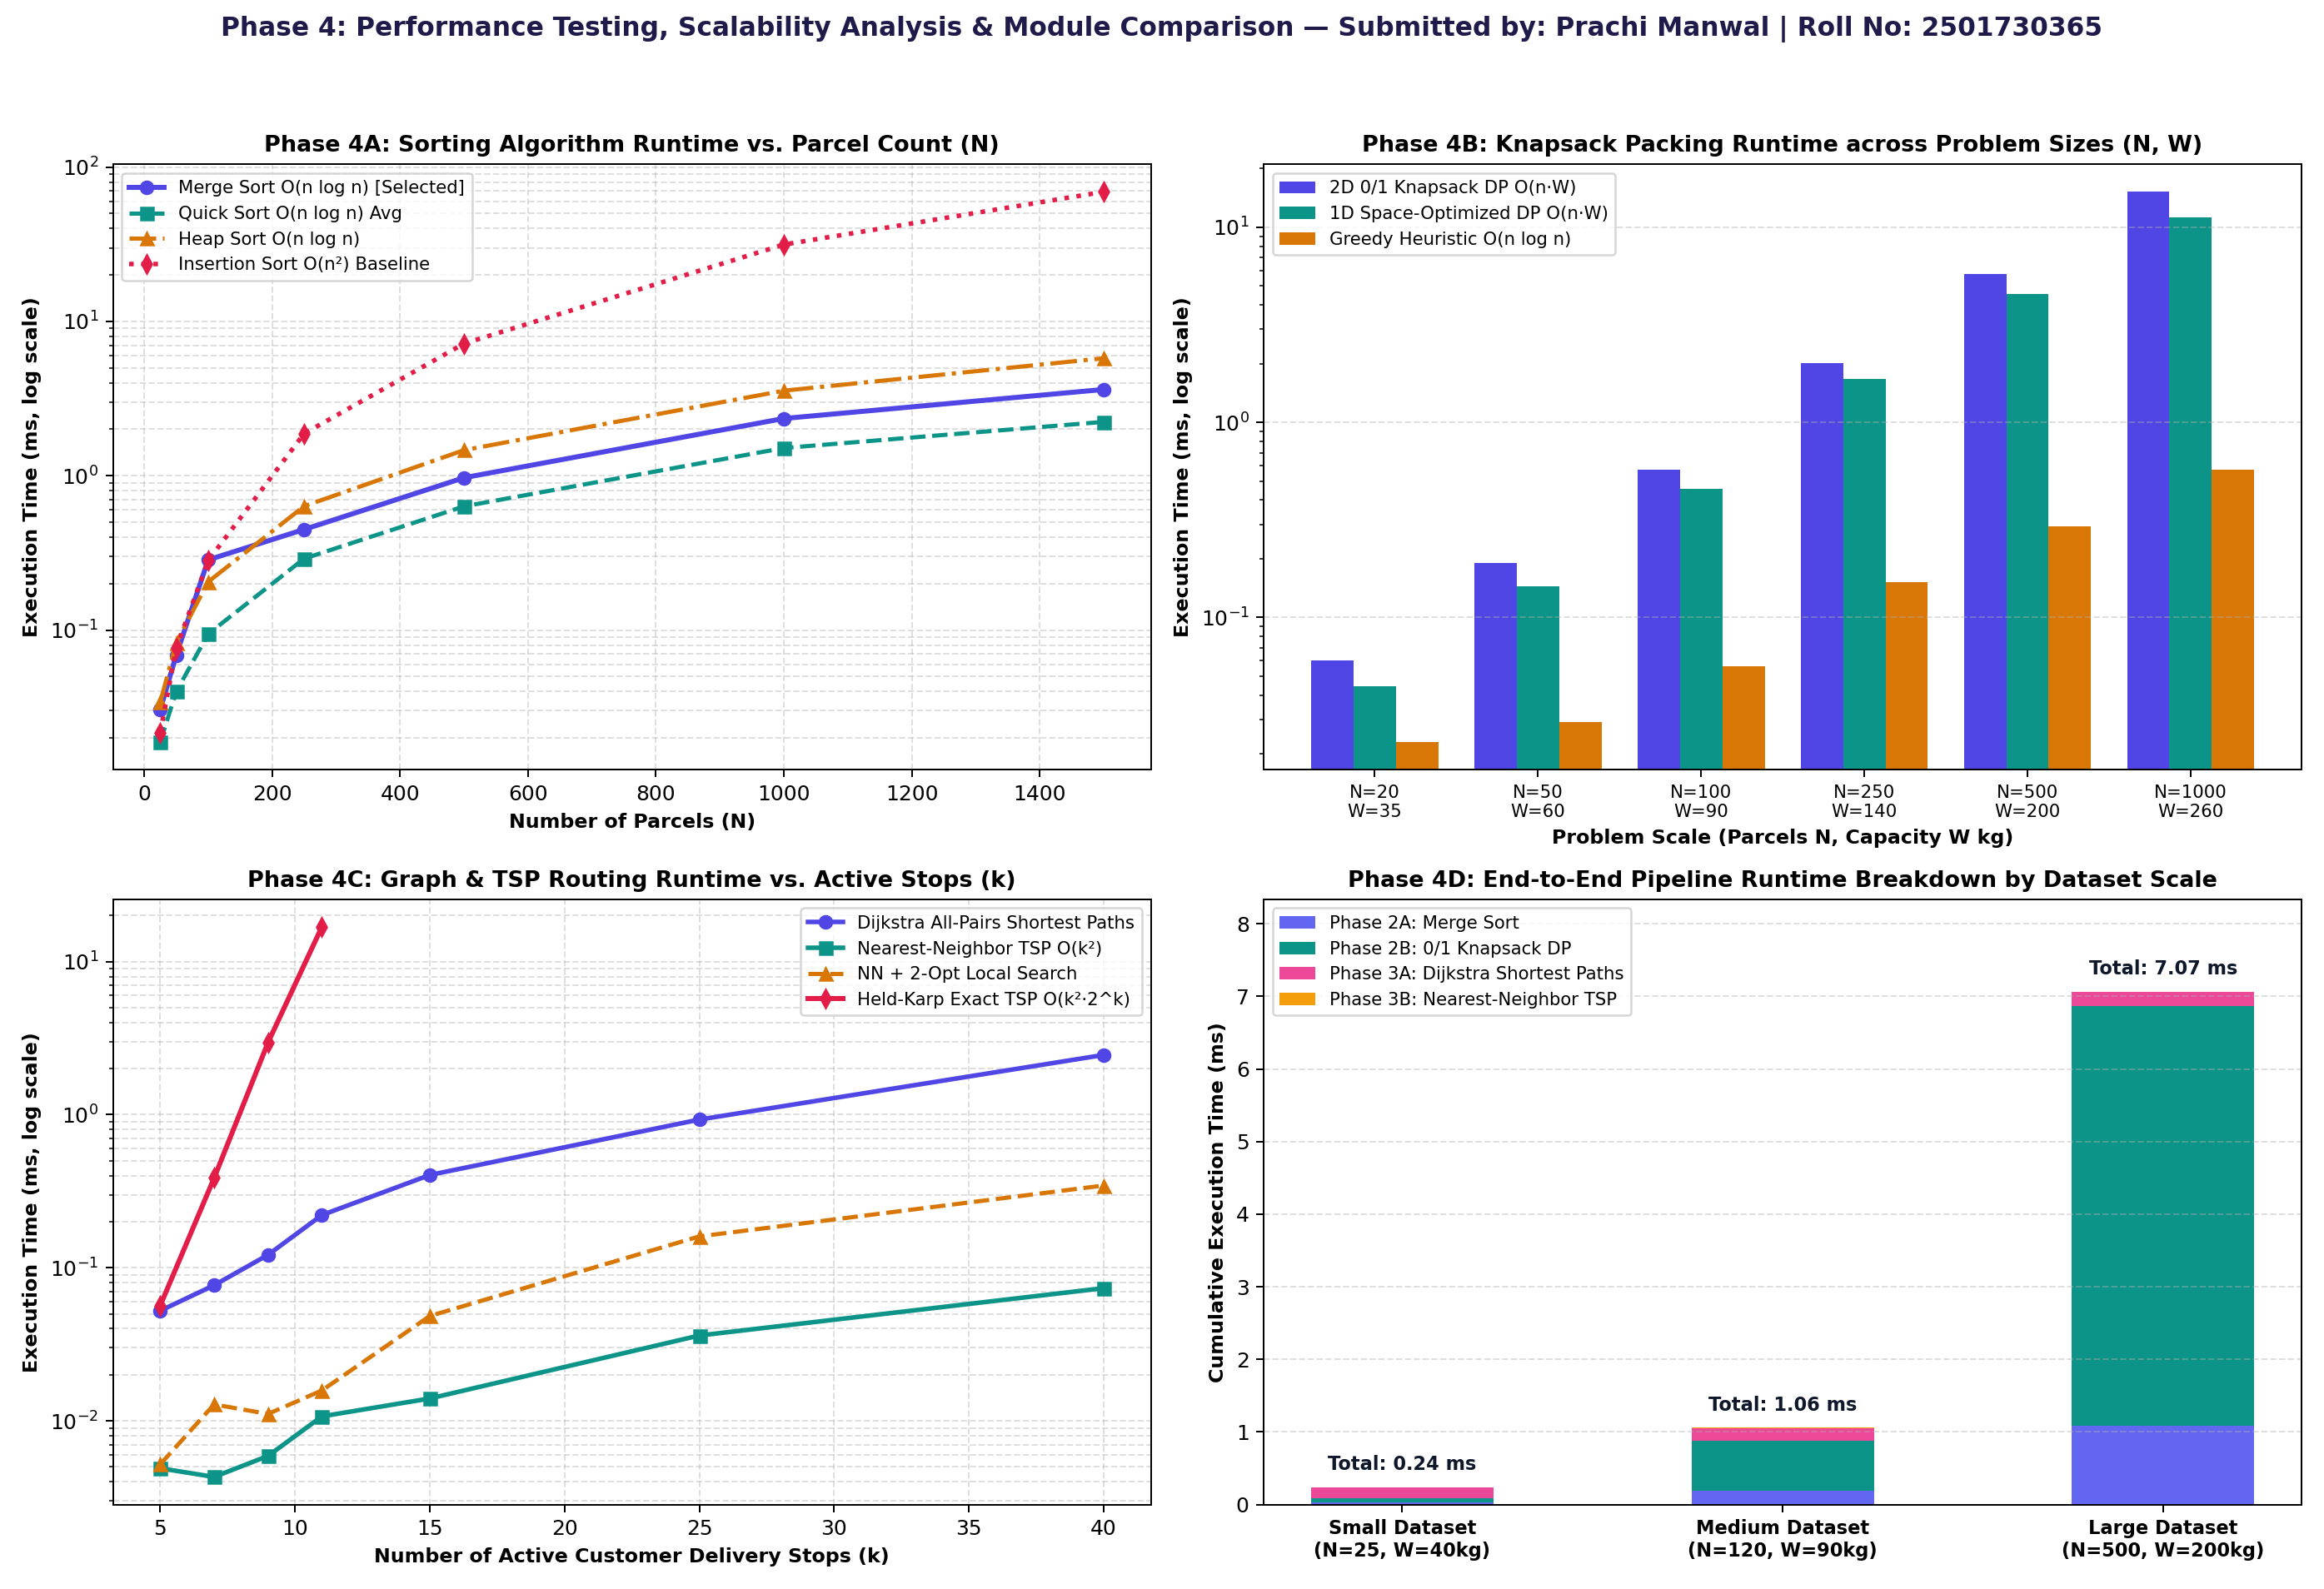

In [4]:
from src.benchmark import (
    run_sorting_benchmarks, run_knapsack_benchmarks,
    run_routing_benchmarks, run_end_to_end_dataset_comparison
)
from src.visualizer import plot_phase4_runtime_charts

sorting_bench = run_sorting_benchmarks()
knapsack_bench = run_knapsack_benchmarks()
routing_bench = run_routing_benchmarks()
e2e_bench = run_end_to_end_dataset_comparison(city_graph)

print("=== 1. SORTING SCALABILITY BENCHMARK (MS) ===")
print(pd.DataFrame(sorting_bench).to_string(index=False))

print("\n=== 2. KNAPSACK PACKING SCALABILITY & OPTIMALITY BENCHMARK ===")
print(pd.DataFrame(knapsack_bench).to_string(index=False))

print("\n=== 3. GRAPH & TSP ROUTING SCALABILITY BENCHMARK ===")
print(pd.DataFrame(routing_bench).to_string(index=False))

print("\n=== 4. END-TO-END PIPELINE COMPARISON (SMALL vs. MEDIUM vs. LARGE DATASETS) ===")
print(pd.DataFrame(e2e_bench).to_string(index=False))

plot_phase4_runtime_charts(
    sorting_bench, knapsack_bench, routing_bench, e2e_bench,
    IMAGES_DIR / "phase4_runtime_scalability_charts.png"
)

---
## 5. Phase 5: Final Report & Complete Console Execution Trace (20 Marks)

         MINI-COURIER PLANNER — INTEGRATED ALGORITHMIC CAPSTONE SYSTEM (METROSWIFT)
         STUDENT NAME: PRACHI MANWAL  |  ROLL NUMBER: 2501730365
Loaded Sample Manifest : 16 parcels | Total Manifest Weight: 86 kg
Courier Van Capacity   : W = 35 kg | Road Network: |V| = 12 nodes, |E| = 24 edges

PHASE 2A: PARCEL PRIORITIZATION (MERGE SORT BY PRIORITY TIER -> DEADLINE -> VALUE)
------------------------------------------------------------------------------------------------
Rank  ID       Customer                   Dest               Tier          Deadline   Wt(kg)  Value  Density
------------------------------------------------------------------------------------------------
#1    PKG-101  MedLife Trauma Center      Z3 (Health City)   EXPRESS (T1)    1.0 hrs     5 kg    145   29.00
#2    PKG-104  Supreme High Court Chamb   Z2 (Secretariat)   EXPRESS (T1)    1.2 hrs     3 kg    105   35.00
#3    PKG-108  BioGenetics Research Lab   Z7 (Electronic )   EXPRESS (T1)    1.5 hrs     4 kg    

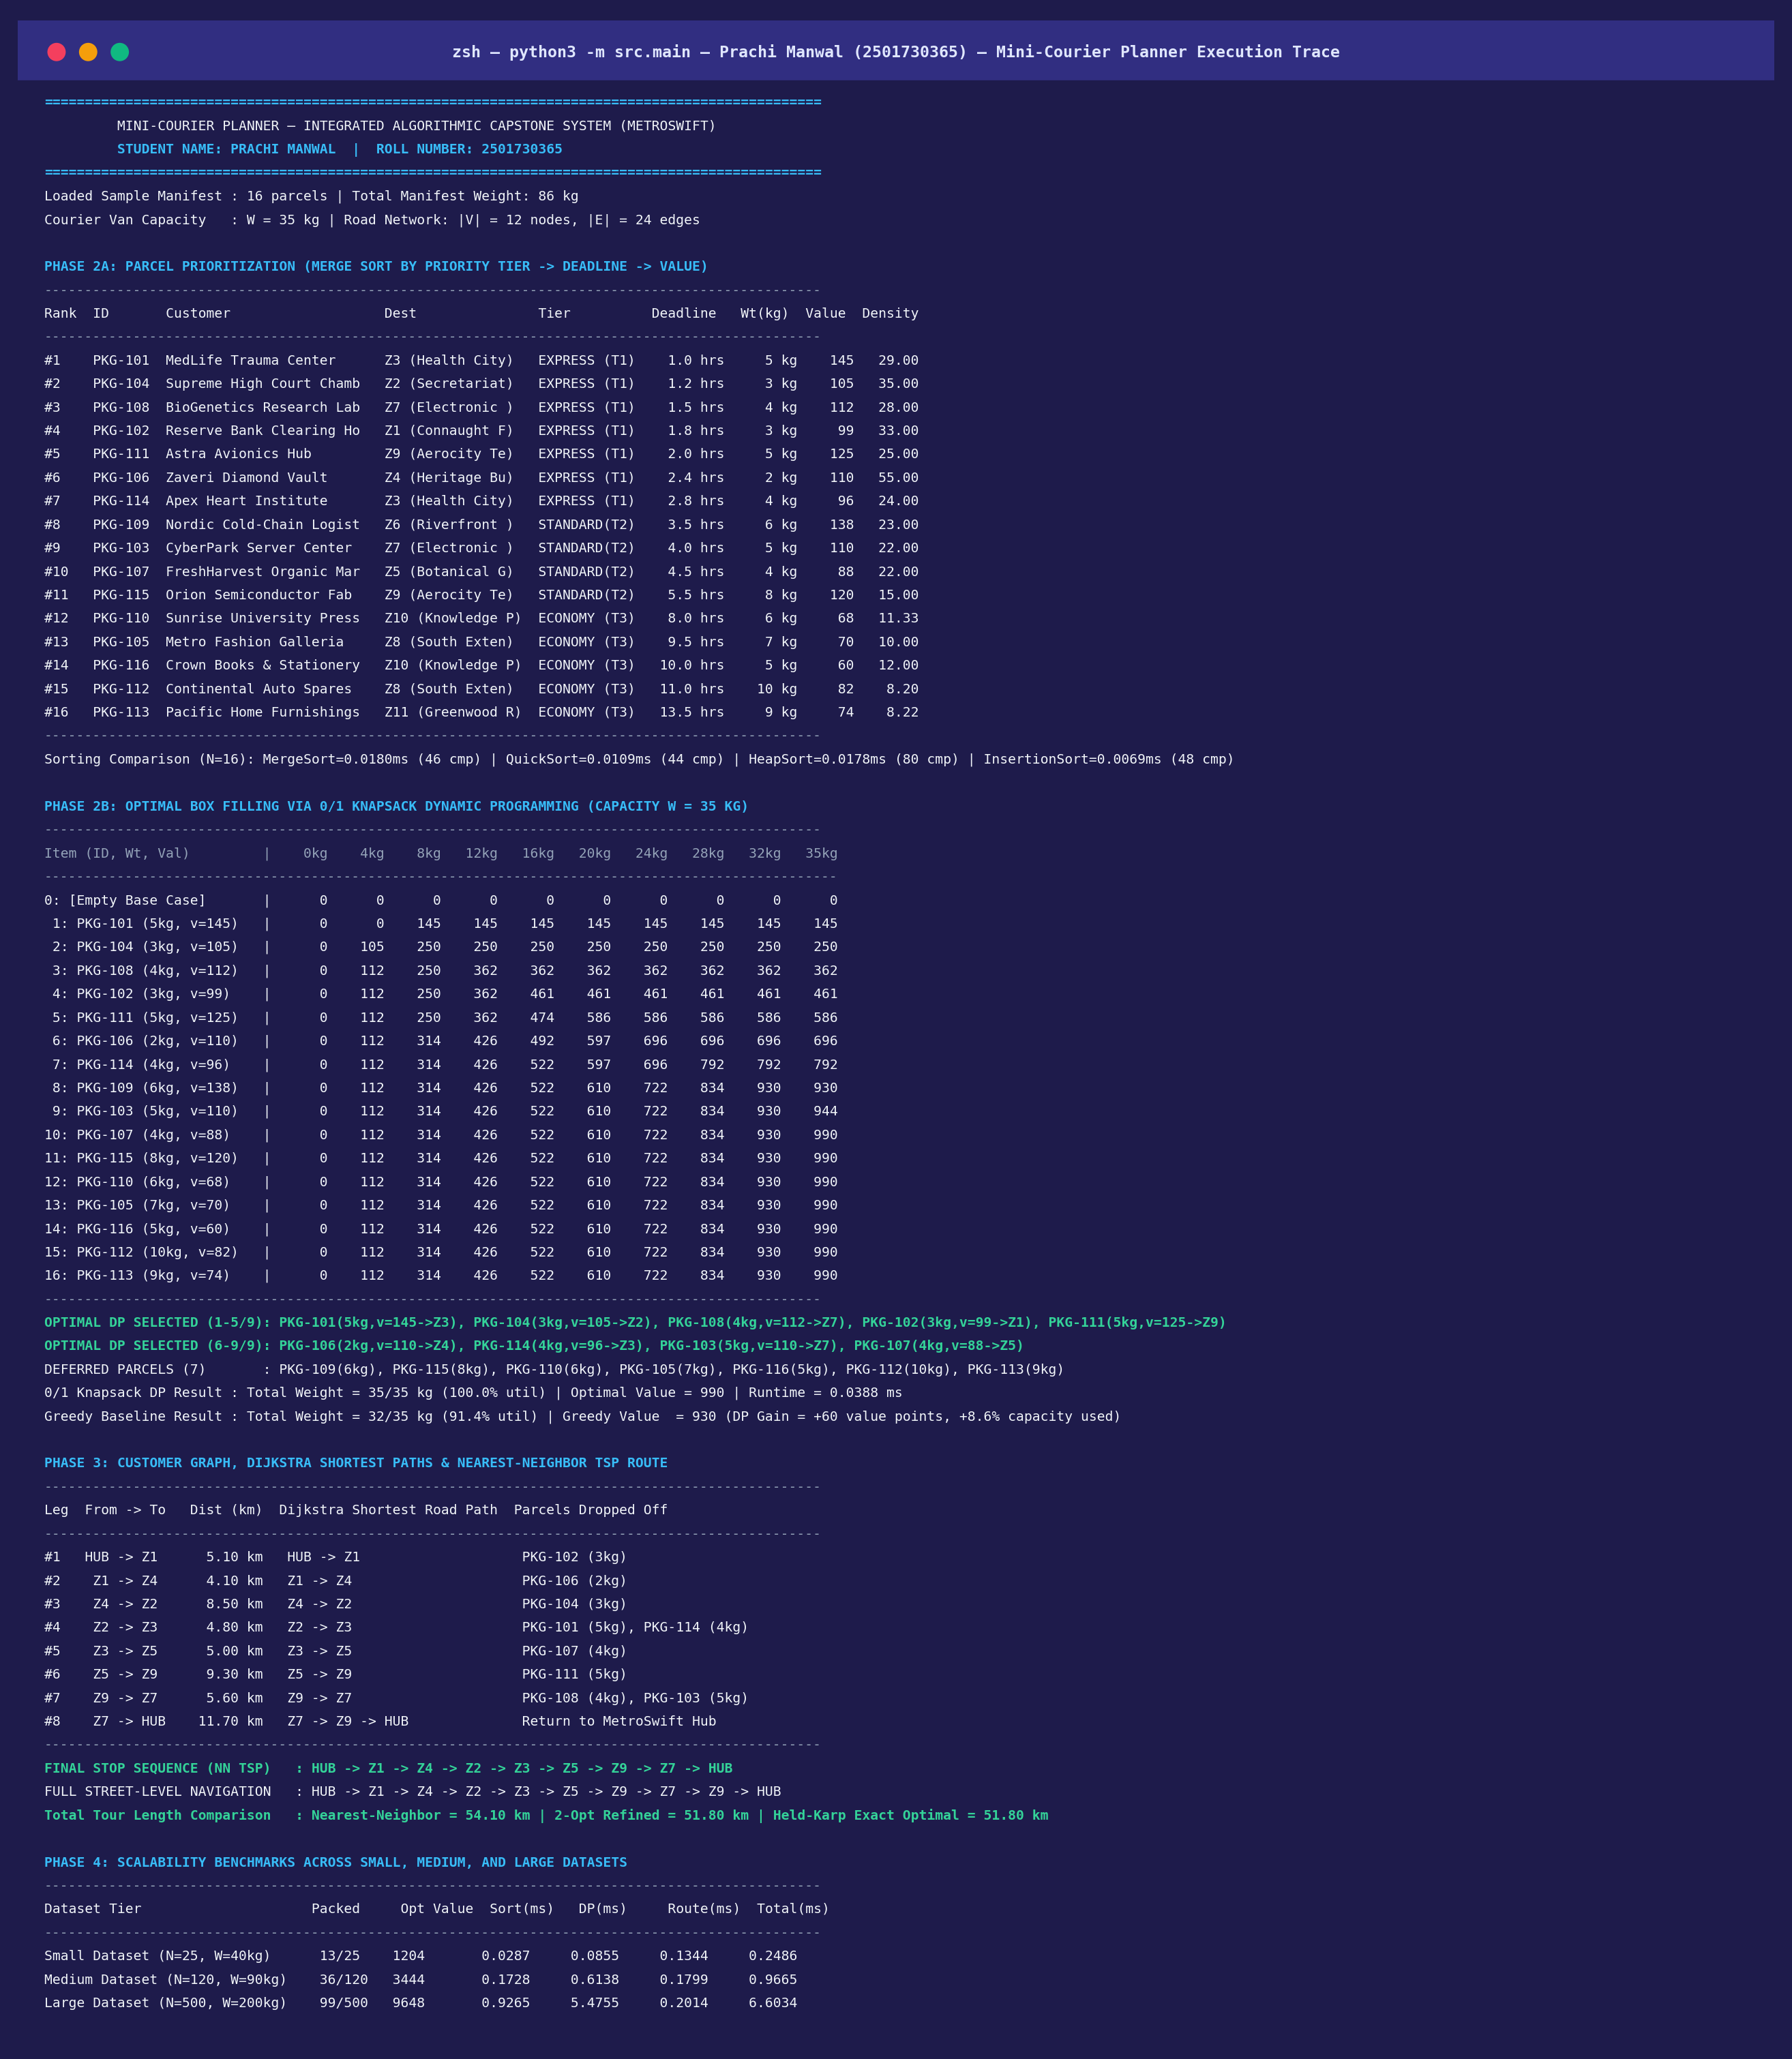

In [5]:
from src.main import execute_capstone_pipeline

pipeline_output = execute_capstone_pipeline(van_capacity_kg=35)
print(pipeline_output["console_report"])